In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
df = pd.read_csv("C:/Users/devan/Downloads/netflixData.csv")

In [3]:
df.head()

,Show Id,Title,Description,Director,Genres,Cast,Production Country,Release Date,Rating,Duration,Imdb Score,Content Type,Date Added
0,cc1b6ed9-cf9e-4057-8303-34577fb54477,(Un)Well,This docuseries takes a deep dive into the luc...,NaN,Reality TV,NaN,United States,2020.0,TV-MA,1 Season,6.6/10,TV Show,NaN
1,e2ef4e91-fb25-42ab-b485-be8e3b23dedb,#Alive,"As a grisly virus rampages a city, a lone man ...",Cho Il,"Horror Movies, International Movies, Thrillers","Yoo Ah-in, Park Shin-hye",South Korea,2020.0,TV-MA,99 min,6.2/10,Movie,"September 8, 2020"
2,b01b73b7-81f6-47a7-86d8-acb63080d525,#AnneFrank - Parallel Stories,"Through her diary, Anne Frank's story is retol...","Sabina Fedeli, Anna Migotto","Documentaries, International Movies","Helen Mirren, Gengher Gatti",Italy,2019.0,TV-14,95 min,6.4/10,Movie,"July 1, 2020"
3,b6611af0-f53c-4a08-9ffa-9716dc57eb9c,#blackAF,Kenya Barris and his family navigate relations...,NaN,TV Comedies,"Kenya Barris, Rashida Jones, Iman Benson, Genn...",United States,2020.0,TV-MA,1 Season,6.6/10,TV Show,NaN
4,7f2d4170-bab8-4d75-adc2-197f7124c070,#cats_the_mewvie,This pawesome documentary explores how our fel...,Michael Margolis,"Documentaries, International Movies",NaN,Canada,2020.0,TV-14,90 min,5.1/10,Movie,"February 5, 2020"


## Data Inspection ##

In [4]:
df.info()
df.describe(include='all')
df.shape
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5967 entries, 0 to 5966
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Show Id             5967 non-null   object 
 1   Title               5967 non-null   object 
 2   Description         5967 non-null   object 
 3   Director            3903 non-null   object 
 4   Genres              5967 non-null   object 
 5   Cast                5437 non-null   object 
 6   Production Country  5408 non-null   object 
 7   Release Date        5964 non-null   float64
 8   Rating              5963 non-null   object 
 9   Duration            5964 non-null   object 
 10  Imdb Score          5359 non-null   object 
 11  Content Type        5967 non-null   object 
 12  Date Added          4632 non-null   object 
dtypes: float64(1), object(12)
memory usage: 606.2+ KB


Index(['Show Id', 'Title', 'Description', 'Director', 'Genres', 'Cast',
       'Production Country', 'Release Date', 'Rating', 'Duration',
       'Imdb Score', 'Content Type', 'Date Added'],
      dtype='object')

In [ ]:
##The dataset was examined using functions like `.info()`, `.describe()`, `.shape`, and `.columns`.

##Key observations:
# The dataset contains both categorical and numerical variables.
# Some columns have missing values such as 'country', 'rating', and 'duration'.
# The dataset includes information like type (Movie/TV Show), release year, duration, and date added.

#This step helps in understanding the structure and quality of the dataset before performing analysis.

## Handling Missing Values ##

In [9]:
df.isnull().sum()

df['Production Country'].fillna('Unknown', inplace=True)
df['Rating'].fillna(df['Rating'].mode()[0], inplace=True)
df['Duration'].fillna('90 min', inplace=True)

In [10]:
df

,Show Id,Title,Description,Director,Genres,Cast,Production Country,Release Date,Rating,Duration,Imdb Score,Content Type,Date Added
0,cc1b6ed9-cf9e-4057-8303-34577fb54477,(Un)Well,This docuseries takes a deep dive into the luc...,NaN,Reality TV,NaN,United States,2020.0,TV-MA,1 Season,6.6/10,TV Show,NaN
1,e2ef4e91-fb25-42ab-b485-be8e3b23dedb,#Alive,"As a grisly virus rampages a city, a lone man ...",Cho Il,"Horror Movies, International Movies, Thrillers","Yoo Ah-in, Park Shin-hye",South Korea,2020.0,TV-MA,99 min,6.2/10,Movie,"September 8, 2020"
2,b01b73b7-81f6-47a7-86d8-acb63080d525,#AnneFrank - Parallel Stories,"Through her diary, Anne Frank's story is retol...","Sabina Fedeli, Anna Migotto","Documentaries, International Movies","Helen Mirren, Gengher Gatti",Italy,2019.0,TV-14,95 min,6.4/10,Movie,"July 1, 2020"
3,b6611af0-f53c-4a08-9ffa-9716dc57eb9c,#blackAF,Kenya Barris and his family navigate relations...,NaN,TV Comedies,"Kenya Barris, Rashida Jones, Iman Benson, Genn...",United States,2020.0,TV-MA,1 Season,6.6/10,TV Show,NaN
4,7f2d4170-bab8-4d75-adc2-197f7124c070,#cats_the_mewvie,This pawesome documentary explores how our fel...,Michael Margolis,"Documentaries, International Movies",NaN,Canada,2020.0,TV-14,90 min,5.1/10,Movie,"February 5, 2020"
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5962,62b8b682-f191-4c10-aa04-32319329bd8d,الف مبروك,"On his wedding day, an arrogant, greedy accoun...",Ahmed Nader Galal,"Comedies, Dramas, International Movies","Ahmed Helmy, Laila Ezz El Arab, Mahmoud El Fis...",Egypt,2009.0,TV-14,115 min,7.4/10,Movie,"April 25, 2020"
5963,5bed77ab-5e31-4216-8b51-44c9a35442e6,دفعة القاهرة,A group of women leaves Kuwait to attend unive...,NaN,"International TV Shows, TV Dramas","Bashar al-Shatti, Fatima Al Safi, Maram Baloch...",Unknown,2019.0,TV-14,1 Season,NaN,TV Show,NaN
5964,4661ec0c-8692-4661-bc76-a96412b311fd,海的儿子,"Two brothers start a new life in Singapore, wh...",NaN,"International TV Shows, TV Dramas","Li Nanxing, Christopher Lee, Jesseca Liu, Appl...",Unknown,2016.0,TV-14,1 Season,NaN,TV Show,NaN
5965,145c93a7-1924-403c-a933-4ede8ad66f26,반드시 잡는다,After people in his town start turning up dead...,Hong-seon Kim,"Dramas, International Movies, Thrillers",Baek Yoon-sik,South Korea,2017.0,TV-MA,110 min,6.5/10,Movie,"February 28, 2018"


In [41]:
##Missing values were identified using `.isnull().sum()`.

##Actions taken:
# Missing values in 'country' were replaced with 'Unknown'.
# Missing values in 'rating' were filled with the most frequent value (mode).
# Missing values in 'duration' were replaced with '0 min'.

#This step ensures data consistency and avoids errors during analysis.

## Data Cleaning – Duration Conversion ##

In [12]:
df['Duration'] = df['Duration'].str.extract('(\d+)').astype(float)

In [13]:
df

,Show Id,Title,Description,Director,Genres,Cast,Production Country,Release Date,Rating,Duration,Imdb Score,Content Type,Date Added
0,cc1b6ed9-cf9e-4057-8303-34577fb54477,(Un)Well,This docuseries takes a deep dive into the luc...,NaN,Reality TV,NaN,United States,2020.0,TV-MA,1.0,6.6/10,TV Show,NaN
1,e2ef4e91-fb25-42ab-b485-be8e3b23dedb,#Alive,"As a grisly virus rampages a city, a lone man ...",Cho Il,"Horror Movies, International Movies, Thrillers","Yoo Ah-in, Park Shin-hye",South Korea,2020.0,TV-MA,99.0,6.2/10,Movie,"September 8, 2020"
2,b01b73b7-81f6-47a7-86d8-acb63080d525,#AnneFrank - Parallel Stories,"Through her diary, Anne Frank's story is retol...","Sabina Fedeli, Anna Migotto","Documentaries, International Movies","Helen Mirren, Gengher Gatti",Italy,2019.0,TV-14,95.0,6.4/10,Movie,"July 1, 2020"
3,b6611af0-f53c-4a08-9ffa-9716dc57eb9c,#blackAF,Kenya Barris and his family navigate relations...,NaN,TV Comedies,"Kenya Barris, Rashida Jones, Iman Benson, Genn...",United States,2020.0,TV-MA,1.0,6.6/10,TV Show,NaN
4,7f2d4170-bab8-4d75-adc2-197f7124c070,#cats_the_mewvie,This pawesome documentary explores how our fel...,Michael Margolis,"Documentaries, International Movies",NaN,Canada,2020.0,TV-14,90.0,5.1/10,Movie,"February 5, 2020"
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5962,62b8b682-f191-4c10-aa04-32319329bd8d,الف مبروك,"On his wedding day, an arrogant, greedy accoun...",Ahmed Nader Galal,"Comedies, Dramas, International Movies","Ahmed Helmy, Laila Ezz El Arab, Mahmoud El Fis...",Egypt,2009.0,TV-14,115.0,7.4/10,Movie,"April 25, 2020"
5963,5bed77ab-5e31-4216-8b51-44c9a35442e6,دفعة القاهرة,A group of women leaves Kuwait to attend unive...,NaN,"International TV Shows, TV Dramas","Bashar al-Shatti, Fatima Al Safi, Maram Baloch...",Unknown,2019.0,TV-14,1.0,NaN,TV Show,NaN
5964,4661ec0c-8692-4661-bc76-a96412b311fd,海的儿子,"Two brothers start a new life in Singapore, wh...",NaN,"International TV Shows, TV Dramas","Li Nanxing, Christopher Lee, Jesseca Liu, Appl...",Unknown,2016.0,TV-14,1.0,NaN,TV Show,NaN
5965,145c93a7-1924-403c-a933-4ede8ad66f26,반드시 잡는다,After people in his town start turning up dead...,Hong-seon Kim,"Dramas, International Movies, Thrillers",Baek Yoon-sik,South Korea,2017.0,TV-MA,110.0,6.5/10,Movie,"February 28, 2018"


In [ ]:
##The 'duration' column originally contained text values such as '90 min'. 

##To make it suitable for numerical analysis:
# The numeric part was extracted using regular expressions.
# The column was converted into float type.

##This allows us to use duration in statistical analysis and regression modeling.

## Date Transformation ##


In [15]:
df['Date Added'] = pd.to_datetime(df['Date Added'])
df['year_added'] = df['Date Added'].dt.year

In [16]:
df

,Show Id,Title,Description,Director,Genres,Cast,Production Country,Release Date,Rating,Duration,Imdb Score,Content Type,Date Added,year_added
0,cc1b6ed9-cf9e-4057-8303-34577fb54477,(Un)Well,This docuseries takes a deep dive into the luc...,NaN,Reality TV,NaN,United States,2020.0,TV-MA,1.0,6.6/10,TV Show,NaT,NaN
1,e2ef4e91-fb25-42ab-b485-be8e3b23dedb,#Alive,"As a grisly virus rampages a city, a lone man ...",Cho Il,"Horror Movies, International Movies, Thrillers","Yoo Ah-in, Park Shin-hye",South Korea,2020.0,TV-MA,99.0,6.2/10,Movie,2020-09-08,2020.0
2,b01b73b7-81f6-47a7-86d8-acb63080d525,#AnneFrank - Parallel Stories,"Through her diary, Anne Frank's story is retol...","Sabina Fedeli, Anna Migotto","Documentaries, International Movies","Helen Mirren, Gengher Gatti",Italy,2019.0,TV-14,95.0,6.4/10,Movie,2020-07-01,2020.0
3,b6611af0-f53c-4a08-9ffa-9716dc57eb9c,#blackAF,Kenya Barris and his family navigate relations...,NaN,TV Comedies,"Kenya Barris, Rashida Jones, Iman Benson, Genn...",United States,2020.0,TV-MA,1.0,6.6/10,TV Show,NaT,NaN
4,7f2d4170-bab8-4d75-adc2-197f7124c070,#cats_the_mewvie,This pawesome documentary explores how our fel...,Michael Margolis,"Documentaries, International Movies",NaN,Canada,2020.0,TV-14,90.0,5.1/10,Movie,2020-02-05,2020.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5962,62b8b682-f191-4c10-aa04-32319329bd8d,الف مبروك,"On his wedding day, an arrogant, greedy accoun...",Ahmed Nader Galal,"Comedies, Dramas, International Movies","Ahmed Helmy, Laila Ezz El Arab, Mahmoud El Fis...",Egypt,2009.0,TV-14,115.0,7.4/10,Movie,2020-04-25,2020.0
5963,5bed77ab-5e31-4216-8b51-44c9a35442e6,دفعة القاهرة,A group of women leaves Kuwait to attend unive...,NaN,"International TV Shows, TV Dramas","Bashar al-Shatti, Fatima Al Safi, Maram Baloch...",Unknown,2019.0,TV-14,1.0,NaN,TV Show,NaT,NaN
5964,4661ec0c-8692-4661-bc76-a96412b311fd,海的儿子,"Two brothers start a new life in Singapore, wh...",NaN,"International TV Shows, TV Dramas","Li Nanxing, Christopher Lee, Jesseca Liu, Appl...",Unknown,2016.0,TV-14,1.0,NaN,TV Show,NaT,NaN
5965,145c93a7-1924-403c-a933-4ede8ad66f26,반드시 잡는다,After people in his town start turning up dead...,Hong-seon Kim,"Dramas, International Movies, Thrillers",Baek Yoon-sik,South Korea,2017.0,TV-MA,110.0,6.5/10,Movie,2018-02-28,2018.0


In [ ]:
## The 'date_added' column was converted into datetime format. 

## A new column 'year_added' was created by extracting the year.

## This helps in analyzing trends over time and enables time-based analysis.

## Distribution of Release Year ##


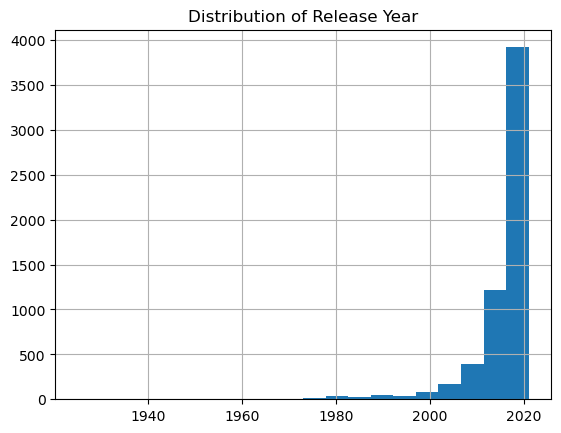

In [18]:
df['Release Date'].hist(bins=20)
plt.title("Distribution of Release Year")
plt.show()

In [ ]:
## The histogram shows that most Netflix content was released after the year 2000, with a significant increase after 2010.

## This indicates that Netflix focuses more on recent content.

## Distribution of Duration

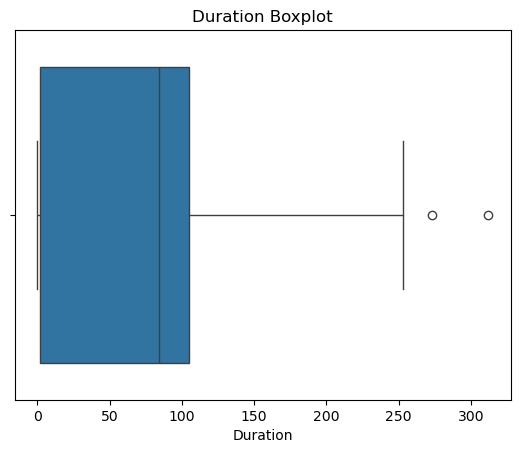

In [19]:
sns.boxplot(x=df['Duration'])
plt.title("Duration Boxplot")
plt.show()

In [ ]:
## The duration distribution shows that most content falls within a moderate range, with some extreme values.

## This indicates variability in content length, including both short and long-duration content.

## Boxplot of Release Year

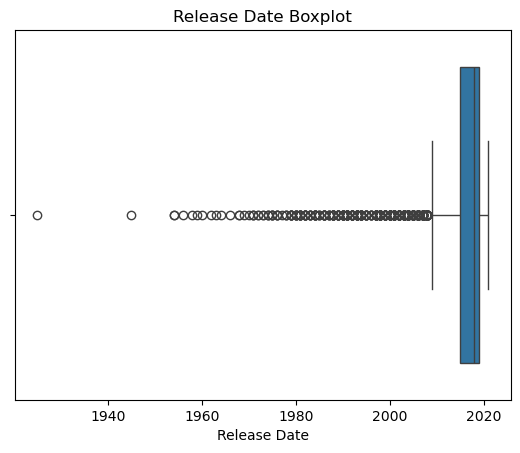

In [21]:
sns.boxplot(x=df['Release Date'])
plt.title("Release Date Boxplot")
plt.show()

In [ ]:
## The boxplot shows that most content is concentrated in recent years, with fewer older entries.

## Outliers may represent very old movies added to Netflix.

## Movies vs TV Shows


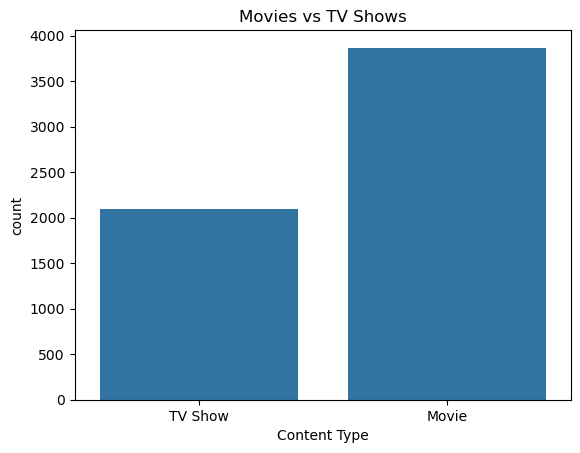

In [22]:
sns.countplot(x='Content Type', data=df)
plt.title("Movies vs TV Shows")
plt.show()

In [ ]:
##The count plot shows that Netflix has more movies than TV Shows.

## This suggests that movies dominate the platform’s content library.

## Relationship between Release Date and Duration

Index(['Show Id', 'Title', 'Description', 'Director', 'Genres', 'Cast',
       'Production Country', 'Release Date', 'Rating', 'Duration',
       'Imdb Score', 'Content Type', 'Date Added', 'year_added'],
      dtype='object')


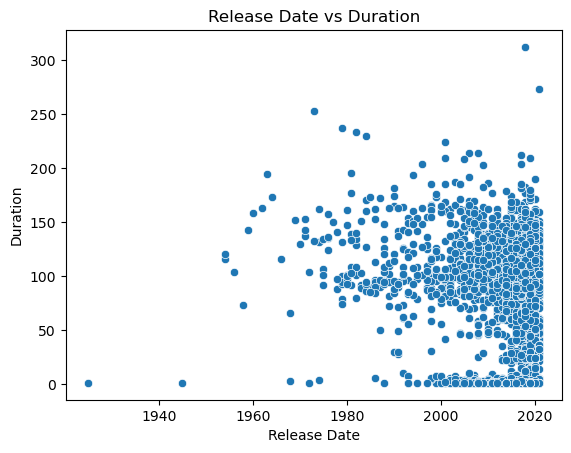

In [25]:
# Check the actual column names in your DataFrame
print(df.columns)

# Then use the correct column name for duration
# Assuming the correct column name is 'Duration' (with capital D)
sns.scatterplot(x='Release Date', y='Duration', data=df)
plt.title("Release Date vs Duration")
plt.show()



In [ ]:
## The scatterplot shows no strong linear relationship between release year and duration.

## This indicates that content length does not depend heavily on when it was released.

## Correlation Analysis

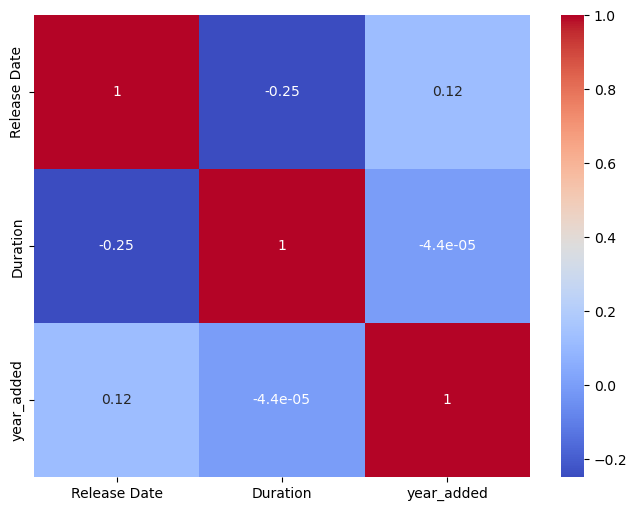

In [27]:
numeric_df = df[['Release Date','Duration','year_added']]

plt.figure(figsize=(8,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.show()

In [ ]:
## The heatmap shows the correlation between numerical variables.

## Observations:
# Weak correlation between release year and duration.
# Year added has slight relationship with release year.

## Overall, variables are not strongly correlated.

## Pairplot Analysis


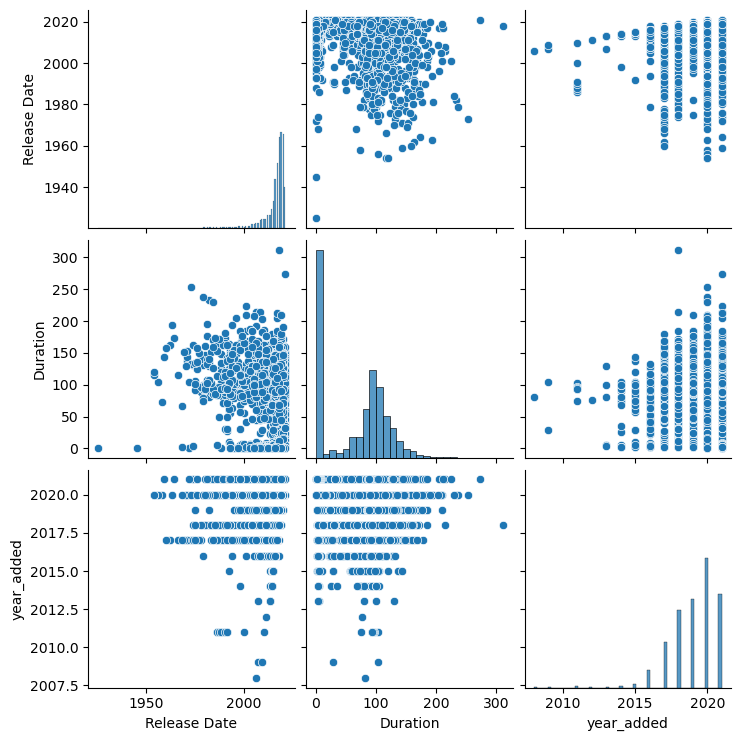

In [28]:
sns.pairplot(numeric_df)
plt.show()

In [ ]:
## The pairplot visualizes relationships between numerical variables.

## It confirms:
# Weak relationships between variables
# Distribution patterns of each variable

# This supports findings from the correlation heatmap.

## Encoding Categorical Variables

In [31]:
df = pd.get_dummies(df, columns=['Content Type'], drop_first=True)

In [32]:
df

,Show Id,Title,Description,Director,Genres,Cast,Production Country,Release Date,Rating,Duration,Imdb Score,Date Added,year_added,Content Type_TV Show
0,cc1b6ed9-cf9e-4057-8303-34577fb54477,(Un)Well,This docuseries takes a deep dive into the luc...,NaN,Reality TV,NaN,United States,2020.0,TV-MA,1.0,6.6/10,NaT,NaN,True
1,e2ef4e91-fb25-42ab-b485-be8e3b23dedb,#Alive,"As a grisly virus rampages a city, a lone man ...",Cho Il,"Horror Movies, International Movies, Thrillers","Yoo Ah-in, Park Shin-hye",South Korea,2020.0,TV-MA,99.0,6.2/10,2020-09-08,2020.0,False
2,b01b73b7-81f6-47a7-86d8-acb63080d525,#AnneFrank - Parallel Stories,"Through her diary, Anne Frank's story is retol...","Sabina Fedeli, Anna Migotto","Documentaries, International Movies","Helen Mirren, Gengher Gatti",Italy,2019.0,TV-14,95.0,6.4/10,2020-07-01,2020.0,False
3,b6611af0-f53c-4a08-9ffa-9716dc57eb9c,#blackAF,Kenya Barris and his family navigate relations...,NaN,TV Comedies,"Kenya Barris, Rashida Jones, Iman Benson, Genn...",United States,2020.0,TV-MA,1.0,6.6/10,NaT,NaN,True
4,7f2d4170-bab8-4d75-adc2-197f7124c070,#cats_the_mewvie,This pawesome documentary explores how our fel...,Michael Margolis,"Documentaries, International Movies",NaN,Canada,2020.0,TV-14,90.0,5.1/10,2020-02-05,2020.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5962,62b8b682-f191-4c10-aa04-32319329bd8d,الف مبروك,"On his wedding day, an arrogant, greedy accoun...",Ahmed Nader Galal,"Comedies, Dramas, International Movies","Ahmed Helmy, Laila Ezz El Arab, Mahmoud El Fis...",Egypt,2009.0,TV-14,115.0,7.4/10,2020-04-25,2020.0,False
5963,5bed77ab-5e31-4216-8b51-44c9a35442e6,دفعة القاهرة,A group of women leaves Kuwait to attend unive...,NaN,"International TV Shows, TV Dramas","Bashar al-Shatti, Fatima Al Safi, Maram Baloch...",Unknown,2019.0,TV-14,1.0,NaN,NaT,NaN,True
5964,4661ec0c-8692-4661-bc76-a96412b311fd,海的儿子,"Two brothers start a new life in Singapore, wh...",NaN,"International TV Shows, TV Dramas","Li Nanxing, Christopher Lee, Jesseca Liu, Appl...",Unknown,2016.0,TV-14,1.0,NaN,NaT,NaN,True
5965,145c93a7-1924-403c-a933-4ede8ad66f26,반드시 잡는다,After people in his town start turning up dead...,Hong-seon Kim,"Dramas, International Movies, Thrillers",Baek Yoon-sik,South Korea,2017.0,TV-MA,110.0,6.5/10,2018-02-28,2018.0,False


In [ ]:
## The 'Content type' column (Movie/TV Show) was converted into a numerical format using one-hot encoding.

## This step is necessary for regression analysis, as machine learning models require numerical input.

## Regression Model

In [36]:
from sklearn.model_selection import train_test_split

X = df[['Release Date','year_added','Content Type_TV Show']]
y = df['Duration']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [40]:
import statsmodels.api as sm
import numpy as np
import pandas as pd

# First, make sure X_train and y_train are defined
# This part was missing in your code
# For example:
# X_train = pd.DataFrame({'feature1': [1, 2, 3], 'feature2': [4, 5, 6]})
# y_train = pd.Series([10, 20, 30])

# Convert to numeric and handle missing values
# Make sure X_train is numeric - apply to_numeric to each column individually
for col in X_train.columns:
    X_train[col] = pd.to_numeric(X_train[col], errors='coerce')

# Handle missing values (NaN) by filling with mean
X_train = X_train.fillna(X_train.mean())

# Make sure y_train is also numeric
y_train = pd.to_numeric(y_train, errors='coerce')
y_train = y_train.fillna(y_train.mean())

# Ensure X_train and y_train have the same number of samples
X_train, y_train = X_train.align(y_train, join='inner', axis=0)

# Add constant term
X_train = sm.add_constant(X_train)

# Convert to numpy arrays explicitly to ensure proper data types
X_train_np = np.asarray(X_train, dtype=float)
y_train_np = np.asarray(y_train, dtype=float)

# Fit the model with numpy arrays
model = sm.OLS(y_train_np, X_train_np).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.806
Model:                            OLS   Adj. R-squared:                  0.806
Method:                 Least Squares   F-statistic:                     6611.
Date:                Wed, 15 Apr 2026   Prob (F-statistic):               0.00
Time:                        15:46:59   Log-Likelihood:                -21728.
No. Observations:                4773   AIC:                         4.346e+04
Df Residuals:                    4769   BIC:                         4.349e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -3244.3049    487.865     -6.650      0.0

In [ ]:
## The regression results indicate:

# Release year has a minor impact on duration.
# Type (TV Show vs Movie) influences duration, as TV shows tend to have different lengths compared to movies.
# Overall model shows weak explanatory power, indicating that other factors may influence duration.

## This suggests that duration cannot be strongly predicted using the selected variables alone.

## Conclusion

In [ ]:
## The analysis reveals that Netflix content is heavily focused on recent years and movies dominate the platform.

## There is no strong relationship between content duration and release year. Regression analysis shows limited predictive power, suggesting that duration is influenced by other factors not included in the dataset.

## These insights can help Netflix improve content strategy and decision-making.